In [1]:
import ccxt
import pandas as pd

exchange = ccxt.binance()

candles = exchange.fetch_ohlcv("BTC/USDT", timeframe="1h", limit=100)

print(len(candles))
print(candles[0])

100
[1793455200000, 77543.01, 77597.22, 77438.0, 77440.0, 286.45737]


In [2]:
df = pd.DataFrame(
    candles,
    columns=["time", "open", "high", "low", "close", "volume"]
)

df["time"] = pd.to_datetime(df["time"], unit="ms")

df.head()

,time,open,high,low,close,volume
0,2026-10-31 14:00:00,77543.01,77597.22,77438.00,77440.00,286.45737
1,2026-10-31 15:00:00,77440.01,77638.37,77392.01,77622.01,418.87434
2,2026-10-31 16:00:00,77622.01,77696.01,77576.71,77626.27,418.79384
3,2026-10-31 17:00:00,77626.28,77796.01,77568.00,77718.90,412.14100
4,2026-10-31 18:00:00,77718.90,77767.17,77632.00,77635.25,340.79566


In [3]:
print(df.shape)
df.tail(1)

(100, 6)


,time,open,high,low,close,volume
99,2026-11-04 17:00:00,80538.01,80578.5,80277.77,80403.4,606.97163


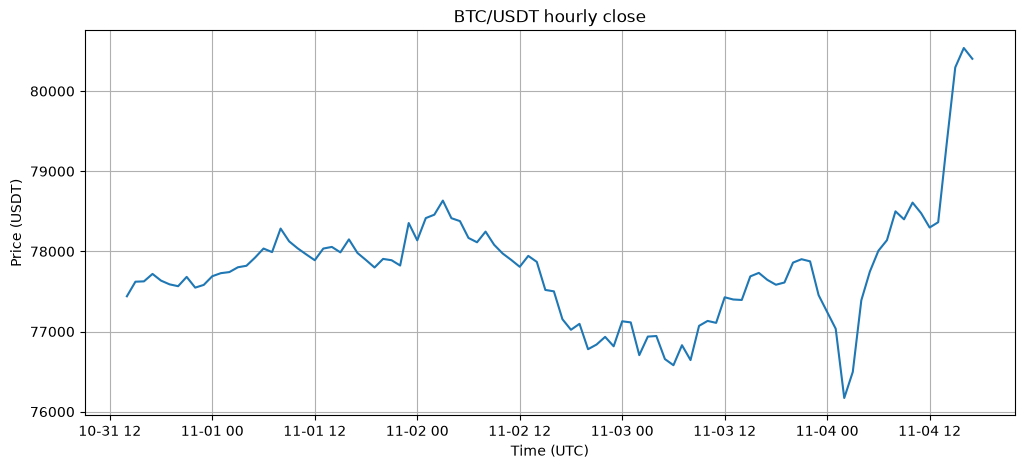

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(df["time"], df["close"])
plt.title("BTC/USDT hourly close")
plt.xlabel("Time (UTC)")
plt.ylabel("Price (USDT)")
plt.grid(True)
plt.show()

In [5]:
import os
import time

os.makedirs("data", exist_ok=True)

symbol = "BTC/USDT"
timeframe = "1h"
days = 180

now = exchange.milliseconds()
since = now - days * 24 * 60 * 60 * 1000

all_candles = []

while since < now:
    batch = exchange.fetch_ohlcv(symbol, timeframe, since=since, limit=1000)
    if not batch:
        break
    all_candles += batch
    since = batch[-1][0] + 1   # continue just after the last candle we got
    print(f"Downloaded {len(all_candles)} candles so far")
    time.sleep(exchange.rateLimit / 1000)   # be polite to the server

Downloaded 1000 candles so far
Downloaded 2000 candles so far
Downloaded 3000 candles so far
Downloaded 4000 candles so far
Downloaded 4320 candles so far


In [6]:
df_all = pd.DataFrame(
    all_candles,
    columns=["time", "open", "high", "low", "close", "volume"]
)
df_all["time"] = pd.to_datetime(df_all["time"], unit="ms")

df_all = (
    df_all.drop_duplicates(subset="time")
          .sort_values("time")
          .reset_index(drop=True)
)

df_all = df_all.iloc[:-1]   # drop the unfinished current-hour candle

df_all.to_csv("data/btc_1h.csv", index=False)

print(df_all.shape)
df_all.head()

(4319, 6)


,time,open,high,low,close,volume
0,2026-05-08 18:00:00,80060.00,80299.99,80059.99,80078.40,470.37331
1,2026-05-08 19:00:00,80078.39,80181.66,79954.54,80179.94,408.77976
2,2026-05-08 20:00:00,80180.00,80299.93,80089.76,80133.09,330.63666
3,2026-05-08 21:00:00,80133.08,80264.00,80116.32,80263.99,269.62208
4,2026-05-08 22:00:00,80264.00,80409.09,80238.42,80262.00,318.15524


In [7]:
df = pd.read_csv("data/btc_1h.csv", parse_dates=["time"])

print("Shape:", df.shape)
print("First candle:", df["time"].min())
print("Last candle: ", df["time"].max())
print()
print("Missing values per column:")
print(df.isna().sum())
print()
print("Gaps between candles:")
print(df["time"].diff().value_counts().head())

Shape: (4319, 6)
First candle: 2026-05-08 18:00:00
Last candle:  2026-11-04 16:00:00

Missing values per column:
time      0
open      0
high      0
low       0
close     0
volume    0
dtype: int64

Gaps between candles:
time
0 days 01:00:00    4318
Name: count, dtype: int64


In [8]:
df.describe()

,time,open,high,low,close,volume
count,4319,4319.000000,4319.000000,4319.000000,4319.000000,4319.000000
mean,2026-08-06 17:00:00,72684.294906,72871.981211,72489.345501,72684.402998,664.482401
min,2026-05-08 18:00:00,58291.700000,58618.650000,57800.190000,58290.170000,55.319060
25%,2026-06-22 17:30:00,64002.975000,64162.975000,63880.000000,64002.975000,322.654940
50%,2026-08-06 17:00:00,76477.460000,76705.710000,76218.000000,76477.450000,485.336240
75%,2026-09-20 16:30:00,80364.700000,80560.000000,80215.730000,80367.835000,779.566895
max,2026-11-04 16:00:00,87166.940000,87395.670000,86636.000000,87166.950000,9262.869650
std,NaN,8534.605032,8544.024458,8524.871939,8534.706582,611.005990
